# Fitting different signals to observed photonic lantern spectra

In [18]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Importing the necessary modules
from PLsim.otf import OTF
from PLsim.scene import Scene, SceneProjector
from PLsim.system.device import Device
from PLsim.system.lantern import generate_unitary_matrix

import hcipy as hc
import numpy as np
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import pandas as pd
from tqdm import tqdm

# Custom modules
import functions
from PhotonicLanternDevice import PhotonicLanternDevice

# Formatting the plots
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.titlesize'] = 20
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['figure.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.title_fontsize'] = 16
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['mathtext.fontset'] = 'cm'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Defining constants

In [19]:
# Constants
MAS_TO_RAD = 1e-3/206265 # [rad/mas]

# Photonic lantern attributes
N_DIM = 65 # Number of pixels in pupil grid
DIAMETER = 10 # [m], diameter of telescope aperture for pupil
FOCAL_RESOLUTION = 1e-6 # [m], resolution of focal grid (make sure this samples LP modes enough but also not truncate the outer parts)
FOCAL_LENGTH = 40 # [m], focal length of telescope (initial value, OTF.from_fiber_params will find an optimal focal ratio)

# Fiber attributes
N_CORE = 1.444 # Index of refraction of the core
N_CLAD = 1.444 - 5.5e-3 # Index of refraction of the cladding
R_CORE = 10e-6 # [m], core radius

# Wavelengths
N_SPEC = 150 # Number of wavelength channels
WAV_MIDDLE = 1282.8 # [nm], Paschen beta line
WAV_WIDTH = 0.1 # [nm]
WAV_BANDWIDTH = 10*WAV_WIDTH # [nm]
WAV_RANGE = np.linspace(WAV_MIDDLE - WAV_BANDWIDTH/2, WAV_MIDDLE + WAV_BANDWIDTH/2, N_SPEC)

## Creating the photonic lantern model

In [20]:
photonic_lantern_device = PhotonicLanternDevice(
    N_DIM=N_DIM,
    DIAMETER=DIAMETER,
    FOCAL_RESOLUTION=FOCAL_RESOLUTION,
    WAV_MIDDLE=WAV_MIDDLE,
    N_CORE=N_CORE,
    N_CLAD=N_CLAD,
    R_CORE=R_CORE,
    FOCAL_LENGTH=FOCAL_LENGTH,
    N_SPEC=N_SPEC
)

Created pupil grid
Created focal grid

Fiber details:
n_core: 1.444
n_clad: 1.4385
r_core: 1e-05 m
ref_wavelength: 1.2828e-06 m

Created aperture
Supported modes:  ['LP01', 'LP11a', 'LP11b', 'LP21a', 'LP21b', 'LP02', 'LP31a', 'LP31b', 'LP12a', 'LP12b']
Number of modes:  10
Created optical transfer function

Computed optical transfer function

Generated unitary matrix of shape: (N_SPEC x N_OUTPUTS x N_OUTPUTS) -> (150, 10, 10)

Device initialized with:
  Lantern matrices: (150, 10, 10)
  PIC matrices: None
  Wavelengths: 150
Initialized device with the unitary matrix

Defined scene
Projected scene onto optical transfer function



## Creating spectra of the two stars

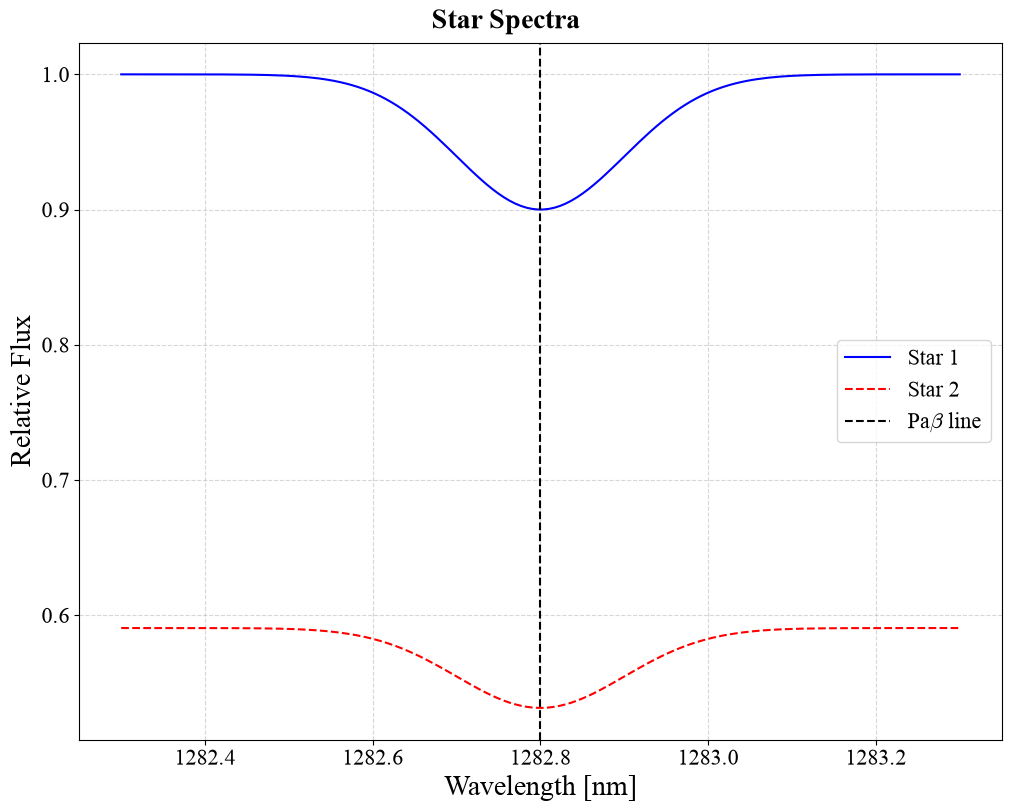

In [38]:
# Mass of the stars
M_1 = 1 # [M_1]
M_2 = 0.9 # [M_1]

# Flux of the continuum of the stars
F_1 = 1
F_2 = F_1 / functions.M_L_relation(M_1, M_2)

# Depth of the line
A_LINE_1 = 0.9
A_LINE_2 = 0.9

# Middle wavelength of each absorption line
WAV_MIDDLE_1 = WAV_MIDDLE
WAV_MIDDLE_2 = WAV_MIDDLE

# Width of each absorption line
WAV_WIDTH_1 = WAV_WIDTH
WAV_WIDTH_2 = WAV_WIDTH

# Spectrum of star 1
star1_spectrum = functions.create_spectrum(F_1, A_LINE_1, WAV_MIDDLE_1, WAV_WIDTH_1, WAV_RANGE)

# Spectrum of star 2
star2_spectrum = functions.create_spectrum(F_2, A_LINE_2, WAV_MIDDLE_2, WAV_WIDTH_2, WAV_RANGE)

# Plotting the spectra
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Star Spectra')

ax.plot(WAV_RANGE, star1_spectrum, label='Star 1', color='b', linestyle='-')
ax.plot(WAV_RANGE, star2_spectrum, label='Star 2', color='r', linestyle='--')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Relative Flux')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend()

plt.show()

## Passing stars into the photonic lantern device

Shape of fractional intensities: (N_SPEC x N_OUTPUTS) -> (150, 10)


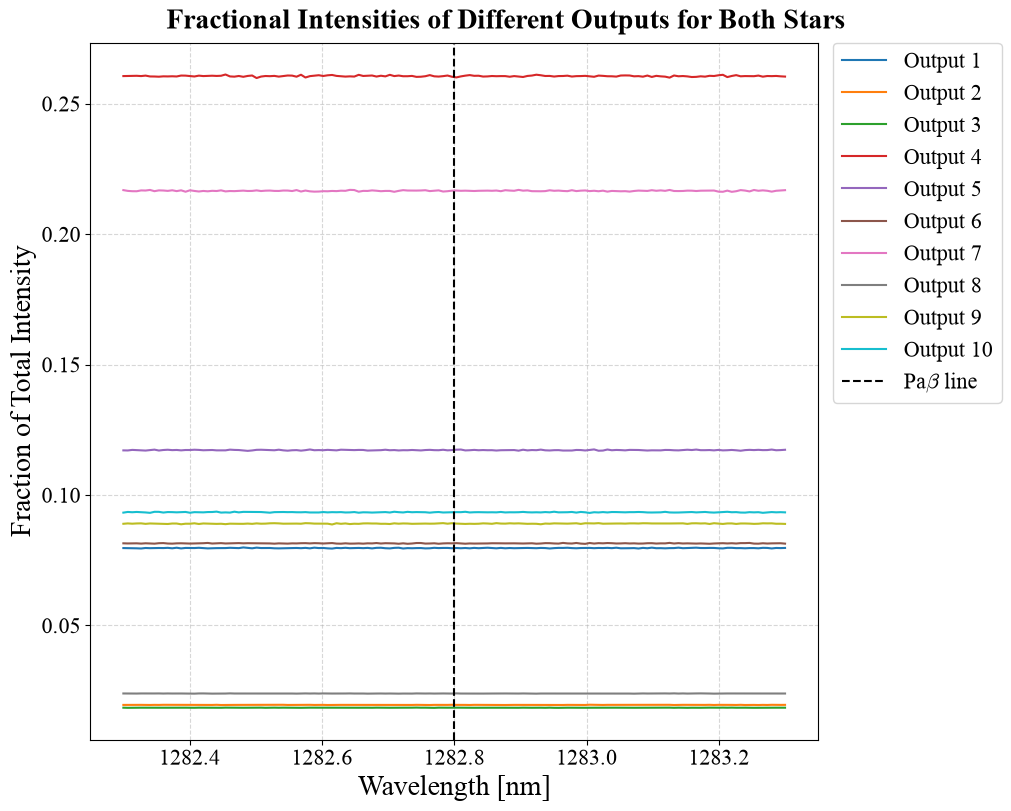

In [39]:
# Star 1 position
star1_x = 0
star1_y = 0
star1_position = np.array([star1_x, star1_y])

# Star 2 position
star2_x = 50
star2_y = 0
star2_position = np.array([star2_x, star2_y])

# Calculating photonic lantern outputs
combined_outputs = photonic_lantern_device.calculate_photonic_lantern_outputs(np.array([star1_position, star2_position]), np.array([star1_spectrum, star2_spectrum]), noise=1e-3)

# Computing the total intensities across all outputs as a function of wavelength
total_intensity = np.sum(combined_outputs, axis=1)

# Computing fractional intensities for the outputs
fractional_intensity = combined_outputs / total_intensity.reshape(-1, 1)

print(f'Shape of fractional intensities: (N_SPEC x N_OUTPUTS) -> {fractional_intensity.shape}')

fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Fractional Intensities of Different Outputs for Both Stars')

for i in range(photonic_lantern_device.N_PORTS):
    ax.plot(WAV_RANGE, fractional_intensity[:, i], label=f'Output {i+1}')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Fraction of Total Intensity')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.show()

## Fitting a single star to the observed photonic lantern outputs

In [40]:
result = photonic_lantern_device.single_fitting(fractional_intensity)

print(f'Global minimum position: {result.x} mas')
print(f'Global minimum error: {result.fun}')

Global minimum position: [-0.13850417  1.76614337] mas
Global minimum error: 1.3427466307646978


## Visualizing error surface

In [41]:
# Defining a grid to try pass into the optimization function
xs = np.linspace(-photonic_lantern_device.angular_extent, photonic_lantern_device.angular_extent, 100)
ys = np.linspace(-photonic_lantern_device.angular_extent, photonic_lantern_device.angular_extent, 100)

XS, YS = np.meshgrid(xs, ys)

# Passing each position into the optimization function
deltas = np.zeros_like(XS)

for i, x in enumerate(xs):
    for j, y in enumerate(ys):
        delta = photonic_lantern_device._single_star_objective((x, y), fractional_intensity)
        deltas[j, i] = delta

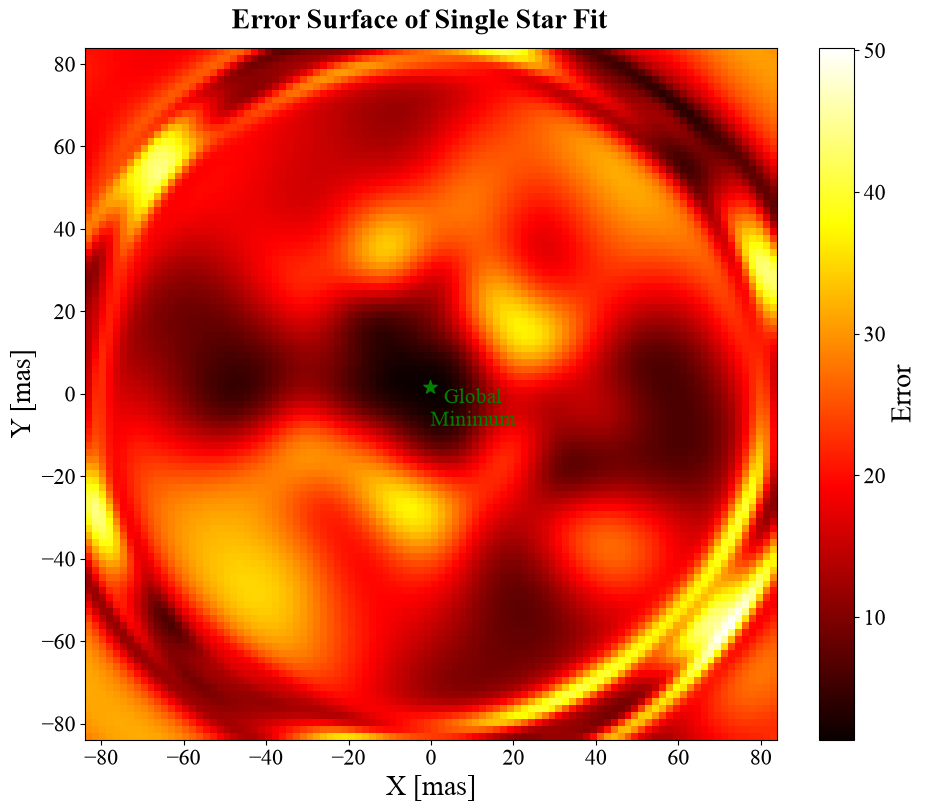

In [42]:
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Error Surface of Single Star Fit')

img = ax.imshow(deltas, origin='lower', extent=[xs[0], xs[-1], ys[0], ys[-1]], cmap='hot')

ax.scatter(result.x[0], result.x[1], marker='*', c='green', s=100)
ax.text(result.x[0], result.x[1], s='Global\nMinimum', fontsize=15, va='top', color='green', ma='center')

fig.colorbar(img, ax=ax, location='right', label=r'Error')

ax.set_xlabel('X [mas]')
ax.set_ylabel('Y [mas]')

ax.set_aspect('equal')

plt.show()

## Fitting a binary signal to the observed photonic lantern outputs
#### Four different stages:
1. Stage 1: Fit a single star like before using `scipy.optimize.differential_evolution` to get a starting point for Star 1.

2. Stage 2: Use the fitted single star position and a grid of Star 2 positions to find local minima and identify potential positions for Star 1 and Star 2 combined. This also solves the spectra using linear least squares.

3. Stage 3: Recover the spectra shapes by calculating the spectra using linear least squares for the optimized position found in Step 2. This will return the depth, center, and width of the spectra, as well as the mass of Star 2.

4. Refine all 12 fitted parameters with linear least squares to find parameter uncertainties and correlations.

In [53]:
guess = np.array([
    [0.9, WAV_MIDDLE, WAV_WIDTH],
    [0.9, WAV_MIDDLE, WAV_WIDTH]
])

true_values = np.array([
    star1_x, star1_y, star2_x, star2_y,
    F_1, A_LINE_1, WAV_MIDDLE_1, WAV_WIDTH_1,
    M_2, A_LINE_2, WAV_MIDDLE_2, WAV_WIDTH_2
])

final_results = photonic_lantern_device.binary_fitting(fractional_intensity, total_intensity, guess, 1, WAV_RANGE, refine=True, true_values=true_values)

fitted_star1_x = final_results[0]
fitted_star1_y = final_results[1]
fitted_star2_x = final_results[2]
fitted_star2_y = final_results[3]
fitted_star1_F = final_results[4]
fitted_star1_depth = final_results[5]
fitted_star1_center = final_results[6]
fitted_star1_width = final_results[7]
fitted_M2 = final_results[8]
fitted_star2_depth = final_results[9]
fitted_star2_center = final_results[10]
fitted_star2_width = final_results[11]

Stage 1:    Position = [-0.138  1.766] mas
            SSR = 1.343e+00
            Time taken: 0.949 seconds

Single star fit result is not within tolerance of 0.001, continuing with binary fitting...



Binary fitting stage 2 (position fitting): 100%|██████████| 100/100 [00:35<00:00,  2.84it/s]


Stage 2:    Star 1 position = [0. 0.] mas
            Star 2 position = [49.996  0.   ] mas
            SSR = 7.557e-06
            Time taken: 35.154 seconds

Stage 3:    Star 1 line (continuum flux, depth, center, width) = [9.9990000e-01 9.0000000e-01 1.2828001e+03 9.9800000e-02]
            Star 2 line (continuum flux, depth, center, width) = [5.9040000e-01 9.0010000e-01 1.2828001e+03 1.0000000e-01]
            M_2 = 0.9000
            Time taken: 0.007 seconds

Stage 4:    Star 1 position = [0. 0.] mas
            Star 2 position = [49.996  0.   ] mas
            Star 1 line (continuum flux, depth, center, width) = [9.9990000e-01 9.0000000e-01 1.2828001e+03 9.9800000e-02]
            Star 2 line (depth, center, width) = [9.0010000e-01 1.2828001e+03 1.0000000e-01]
            M_2 = 0.9000
            SSR = 1.151e-05
            Time taken: 0.094 seconds

                                 fit  uncertainty   true
x1 [mas]                 0.000221583   0.00290582      0
y1 [mas]        

## Plotting the fitted binary spectra

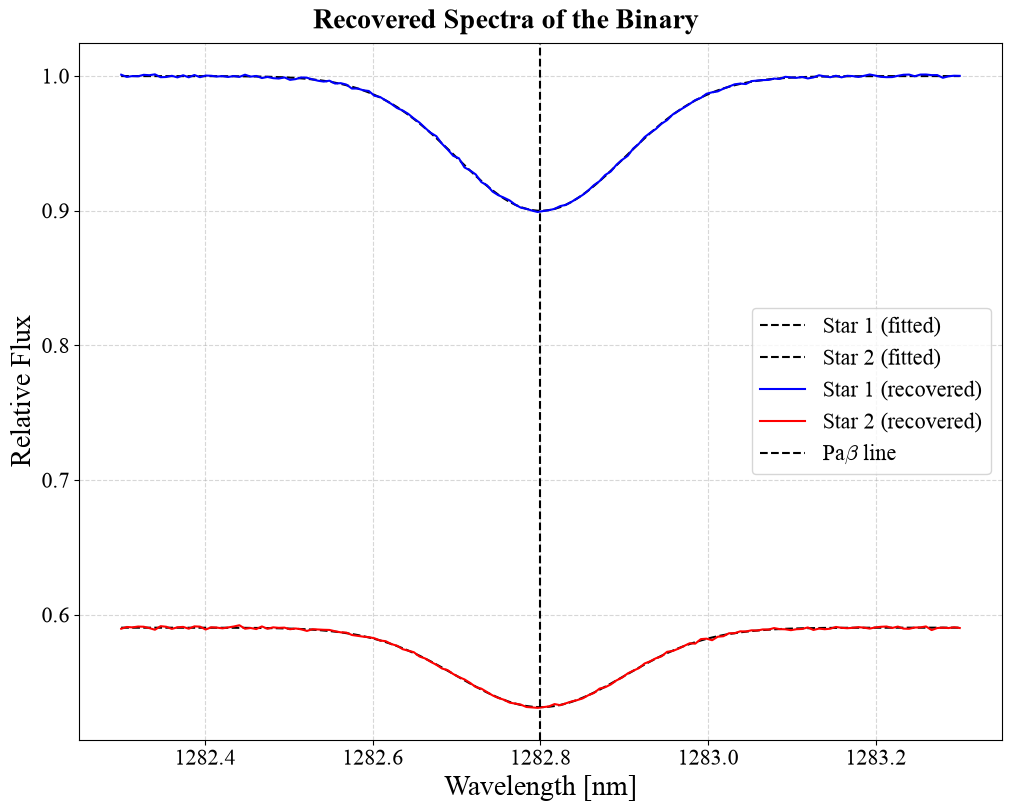

In [56]:
# Plotting the recovered spectra
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Recovered Spectra of the Binary')

fitted_star1_spectrum = functions.create_spectrum(fitted_star1_F, fitted_star1_depth, fitted_star1_center, fitted_star1_width, WAV_RANGE)
fitted_star2_spectrum = functions.create_spectrum(fitted_star1_F / functions.M_L_relation(M_1, fitted_M2), fitted_star2_depth, fitted_star2_center, fitted_star2_width, WAV_RANGE)

ax.plot(WAV_RANGE, fitted_star1_spectrum, color='k', label='Star 1 (fitted)', linestyle='--')
ax.plot(WAV_RANGE, fitted_star2_spectrum, color='k', label='Star 2 (fitted)', linestyle='--')

# ax.plot(WAV_RANGE, star1_spectrum, color='b', label='Star 1 (true)', linestyle='-')
# ax.plot(WAV_RANGE, star2_spectrum, color='r', label='Star 2 (true)', linestyle='-')

ax.plot(WAV_RANGE, photonic_lantern_device.recovered_s1, color='b', label='Star 1 (recovered)', linestyle='-')
ax.plot(WAV_RANGE, photonic_lantern_device.recovered_s2, color='r', label='Star 2 (recovered)', linestyle='-')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Relative Flux')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend()

plt.show()

Stage 1 (single star):  position = [-7.28  4.95] mas, SSR = 2.494e+00


100%|██████████| 11/11 [00:58<00:00,  5.36s/it]


Stage 2 (binary):       positions = [ 0.     0.    49.997  0.   ] mas, SSR = 1.406e-05
Stage 3 (spectra):      star 1 line (F, depth, center, width) = [9.9980000e-01 9.0000000e-01 1.2828001e+03 9.9700000e-02]
                        star 2 line (F, depth, center, width) = [9.99900e-01 8.00000e-01 1.28285e+03 8.00000e-02]
                        M_2 = 1.0000 M_1

Stage 4 (joint fit):
                       fit  uncertainty    true
x1 [mas]       0.000978655   0.00292266       0
y1 [mas]       0.000144237   0.00105296       0
x2 [mas]           49.9974   0.00279898      50
y2 [mas]      -0.000383148   0.00534608       0
M2 [M_1]           1.00002  4.78207e-05       1
a_line_2          0.799983  0.000306085     0.8
center_2 [nm]      1282.85  0.000145066 1282.85
width_2 [nm]     0.0799584  0.000166999    0.08

Correlation matrix:
               x1 [mas]  y1 [mas]  x2 [mas]  y2 [mas]  M2 [M_1]  a_line_2  center_2 [nm]  width_2 [nm]
x1 [mas]           1.00     -0.53      0.60     -0.94     

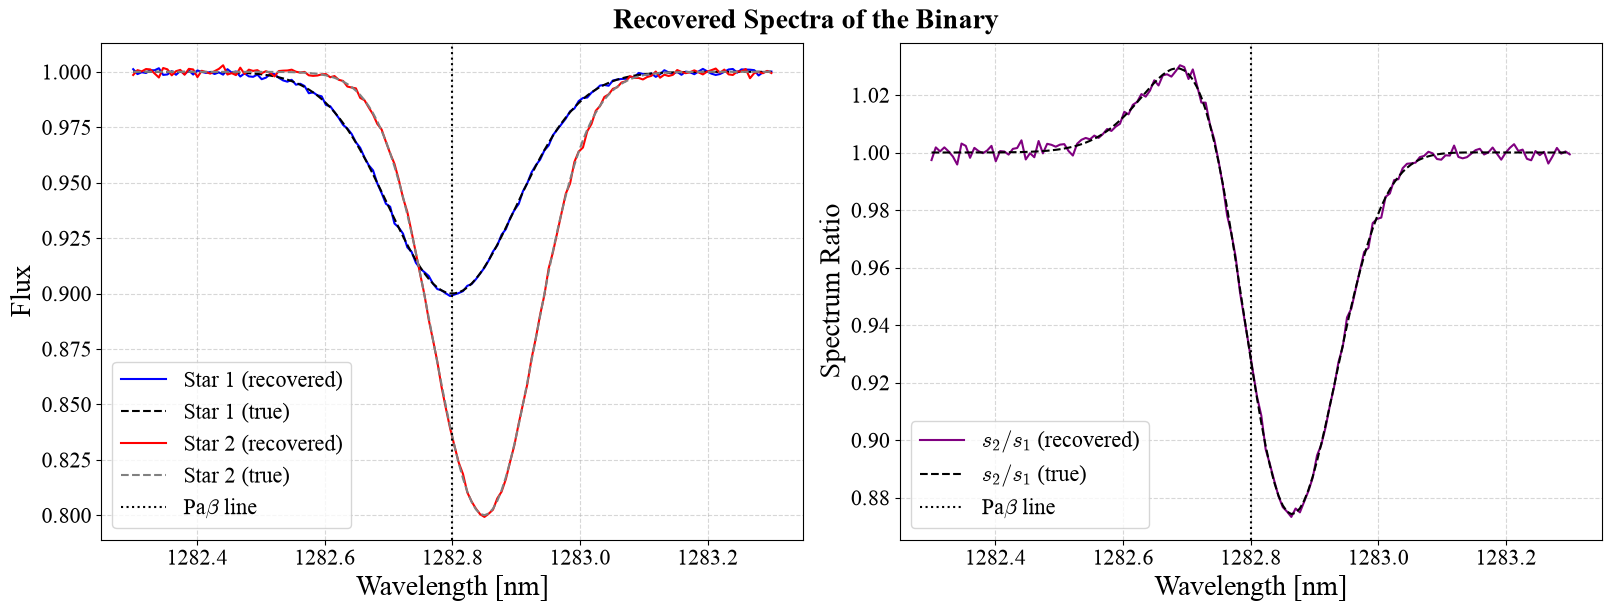

In [42]:
from scipy.optimize import least_squares

# ============================================================
# Example workflow: fitting a binary to the lantern outputs
# ============================================================
# Model: at every wavelength the port intensities are a linear combination of the two point-source responses,
#     I_n(λ) = s1(λ) G_n(θ1) + s2(λ) G_n(θ2)
# so for trial positions (θ1, θ2) the spectra s1(λ), s2(λ) follow from linear least squares.
# Order of the fit:
#   Stage 1: Single-star fit (differential_evolution) to get a starting point for star 1
#   Stage 2: Multistart local fits of the 4 positions (least_squares); spectra solved linearly inside
#   Stage 3: Recover s1(λ), s2(λ), s2/s1 and fit the line + mass of star 2 to the recovered spectrum
#   Stage 4: Joint refinement of all 8 parameters (least_squares) for uncertainties and parameter correlations

# ------------------------------------------------------------
# Test binary with known parameters (stands in for real data)
# ------------------------------------------------------------
def line_spectrum(F, a_line, center, width):
    '''Continuum F with a Gaussian absorption line of relative depth a_line at center [nm] with width [nm].'''
    return F * (1 - (1 - a_line) * np.exp(-0.5 * (WAV_RANGE - center)**2 / width**2))

TRUE_X1, TRUE_Y1 = 0, 0 # [mas]
TRUE_X2, TRUE_Y2 = 50, 0 # [mas]
TRUE_M2 = 1 # [M_1]
TRUE_A2, TRUE_C2, TRUE_W2 = 0.8, WAV_MIDDLE + 0.05, 0.08 # depth, center [nm], width [nm] of star 2's line

M_1, F_1 = 1, 1
true_s1 = line_spectrum(F_1, 0.9, WAV_MIDDLE, WAV_WIDTH)
true_s2 = line_spectrum(F_1 / functions.M_L_relation(M_1, TRUE_M2), TRUE_A2, TRUE_C2, TRUE_W2)

def port_response(x, y) -> np.ndarray:
    '''Port intensities (N_SPEC x N_OUTPUTS) for a unit, flat-spectrum point source at (x, y) [mas].'''
    projected = photonic_lantern_device.scene_projector.compute_point(x * MAS_TO_RAD, y * MAS_TO_RAD).repeat(N_SPEC, axis=2)
    return np.real(photonic_lantern_device.device.calculate_outputs(projected.transpose(2, 0, 1)))

rng = np.random.default_rng(0)
NOISE = 1e-3 # Fractional noise per channel and port

observed_intensities = true_s1[:, None] * port_response(TRUE_X1, TRUE_Y1) + true_s2[:, None] * port_response(TRUE_X2, TRUE_Y2)
observed_intensities *= 1 + NOISE * rng.standard_normal(observed_intensities.shape)

# What is measured: the fractional intensities and the total intensity at each wavelength
observed_total = observed_intensities.sum(axis=1) # (N_SPEC,)
observed_fractions = observed_intensities / observed_total[:, None] # (N_SPEC, N_OUTPUTS)

# ------------------------------------------------------------
# Inner linear solve: spectra for fixed positions
# ------------------------------------------------------------
def solve_spectra(G1, G2, fractions):
    '''
    Solves fractions(λ) ≈ a(λ) G1(λ) + b(λ) G2(λ) at every wavelength by linear least squares.

    Since fractions = I / sum(I), a = s1 / sum(I) and b = s2 / sum(I), so b / a = s2 / s1.

    Returns
    -------
    coeffs : np.ndarray
        (N_SPEC x 2) array of [a(λ), b(λ)]
    model : np.ndarray
        (N_SPEC x N_OUTPUTS) best-fit fractions
    '''
    A = np.stack([G1, G2], axis=2) # (N_SPEC, N_OUTPUTS, 2)
    AtA = np.einsum('lni,lnj->lij', A, A) # (N_SPEC, 2, 2)
    Atf = np.einsum('lni,ln->li', A, fractions) # (N_SPEC, 2)
    coeffs = np.linalg.solve(AtA, Atf[..., None])[..., 0] # (N_SPEC, 2)
    model = np.einsum('lni,li->ln', A, coeffs)
    return coeffs, model

def position_residuals(p, fractions) -> np.ndarray:
    '''Residual vector for positions p = (x1, y1, x2, y2) [mas], with the spectra solved linearly.'''
    _, model = solve_spectra(port_response(p[0], p[1]), port_response(p[2], p[3]), fractions)
    return (fractions - model).ravel()

# ------------------------------------------------------------
# Stage 1: single-star fit (starting point for star 1)
# ------------------------------------------------------------
def single_residuals(p, fractions) -> np.ndarray:
    '''Residual vector for a single star at p = (x, y) [mas]; its spectrum cancels in the fractions.'''
    G = port_response(p[0], p[1])
    return (fractions - G / G.sum(axis=1, keepdims=True)).ravel()

stage1 = differential_evolution(lambda p: np.sum(single_residuals(p, observed_fractions)**2), [(-50, 50), (-50, 50)], seed=0)
print(f'Stage 1 (single star):  position = {np.round(stage1.x, 2)} mas, SSR = {stage1.fun:.3e}')

# ------------------------------------------------------------
# Stage 2: multistart local fits of the 4 positions
# ------------------------------------------------------------
# The binary error surface has many local minima, so start star 2 from a coarse grid of positions
# and keep the best local fit
start_grid = np.arange(-75, 76, 15) # [mas]
min_start_separation = 10 # [mas]

best_fit = None
for x2_start in tqdm(start_grid):
    for y2_start in start_grid:
        if np.hypot(x2_start - stage1.x[0], y2_start - stage1.x[1]) < min_start_separation:
            continue

        fit = least_squares(position_residuals, np.r_[stage1.x, x2_start, y2_start], args=(observed_fractions,), x_scale=10)

        if best_fit is None or fit.cost < best_fit.cost:
            best_fit = fit

best_positions = best_fit.x
print(f'Stage 2 (binary):       positions = {np.round(best_positions, 3)} mas, SSR = {2*best_fit.cost:.3e}')

# ------------------------------------------------------------
# Stage 3: recover the spectra and fit star 2's line and mass
# ------------------------------------------------------------
coeffs, _ = solve_spectra(port_response(*best_positions[:2]), port_response(*best_positions[2:]), observed_fractions)

# The two stars are interchangeable in the model, so call the brighter one star 1
if np.median(coeffs[:, 1]) > np.median(coeffs[:, 0]):
    coeffs = coeffs[:, ::-1]
    best_positions = np.r_[best_positions[2:], best_positions[:2]]

spectrum_ratio = coeffs[:, 1] / coeffs[:, 0] # s2 / s1 (needs only the fractions)
recovered_s1 = coeffs[:, 0] * observed_total # Absolute spectra (also need the total intensity)
recovered_s2 = coeffs[:, 1] * observed_total

def fit_line(spectrum, guess):
    '''Fits (F, a_line, center, width) of line_spectrum to a recovered spectrum.'''
    return least_squares(lambda q: line_spectrum(*q) - spectrum, guess,
                         bounds=([0, 0, WAV_RANGE[0], 1e-3], [np.inf, 2, WAV_RANGE[-1], 1])).x

line1 = fit_line(recovered_s1, [np.median(recovered_s1), 0.9, WAV_MIDDLE, WAV_WIDTH])
line2 = fit_line(recovered_s2, [np.median(recovered_s2), 0.9, WAV_MIDDLE, WAV_WIDTH])

# Invert the mass-luminosity relation (M_1 < 2 branch): F_2 / F_1 = (M_2 / M_1)^5
fitted_M2 = M_1 * (line2[0] / line1[0])**(1/5)

print(f'Stage 3 (spectra):      star 1 line (F, depth, center, width) = {np.round(line1, 4)}')
print(f'                        star 2 line (F, depth, center, width) = {np.round(line2, 4)}')
print(f'                        M_2 = {fitted_M2:.4f} M_1')

# ------------------------------------------------------------
# Stage 4: joint refinement of all 8 parameters
# ------------------------------------------------------------
# Star 1's spectrum is held at its Stage 3 fit; the fractions only constrain s2 / s1
fitted_s1 = line_spectrum(*line1)

def binary_residuals(params, fractions) -> np.ndarray:
    '''Residual vector for params = (x1, y1, x2, y2, M2, a_line_2, center_2, width_2).'''
    x1, y1, x2, y2, M2, a2, c2, w2 = params
    s2 = line_spectrum(line1[0] / functions.M_L_relation(M_1, M2), a2, c2, w2)
    intensities = fitted_s1[:, None] * port_response(x1, y1) + s2[:, None] * port_response(x2, y2)
    return (fractions - intensities / intensities.sum(axis=1, keepdims=True)).ravel()

stage4 = least_squares(
    binary_residuals, np.r_[best_positions, fitted_M2, line2[1:]], args=(observed_fractions,),
    x_scale=[10, 10, 10, 10, 0.1, 0.1, 0.05, 0.05],
)

# Covariance from the Jacobian: C = (J^T J)^-1 * (residual variance)
n_data, n_params = stage4.fun.size, stage4.x.size
residual_variance = 2 * stage4.cost / (n_data - n_params)
covariance = np.linalg.inv(stage4.jac.T @ stage4.jac) * residual_variance
uncertainties = np.sqrt(np.diag(covariance))
correlation = covariance / np.outer(uncertainties, uncertainties)

param_names = ['x1 [mas]', 'y1 [mas]', 'x2 [mas]', 'y2 [mas]', 'M2 [M_1]', 'a_line_2', 'center_2 [nm]', 'width_2 [nm]']
true_values = [TRUE_X1, TRUE_Y1, TRUE_X2, TRUE_Y2, TRUE_M2, TRUE_A2, TRUE_C2, TRUE_W2]

print('\nStage 4 (joint fit):')
print(pd.DataFrame({'fit': stage4.x, 'uncertainty': uncertainties, 'true': true_values}, index=param_names).to_string(float_format='%.6g'))
print('\nCorrelation matrix:')
print(pd.DataFrame(correlation, index=param_names, columns=param_names).to_string(float_format='%.2f'))

# ------------------------------------------------------------
# Plotting recovered spectra
# ------------------------------------------------------------
fig = plt.figure(figsize=(16, 6))
fig.set_constrained_layout(True)
axes = fig.subplots(ncols=2)

fig.suptitle('Recovered Spectra of the Binary')

axes[0].plot(WAV_RANGE, recovered_s1, color='b', label='Star 1 (recovered)')
axes[0].plot(WAV_RANGE, true_s1, color='k', linestyle='--', label='Star 1 (true)')
axes[0].plot(WAV_RANGE, recovered_s2, color='r', label='Star 2 (recovered)')
axes[0].plot(WAV_RANGE, true_s2, color='gray', linestyle='--', label='Star 2 (true)')
axes[0].set_ylabel('Flux')

axes[1].plot(WAV_RANGE, spectrum_ratio, color='purple', label='$s_2/s_1$ (recovered)')
axes[1].plot(WAV_RANGE, true_s2 / true_s1, color='k', linestyle='--', label='$s_2/s_1$ (true)')
axes[1].set_ylabel('Spectrum Ratio')

for ax in axes:
    ax.axvline(WAV_MIDDLE, color='k', linestyle=':', label='Pa$\\beta$ line')
    ax.set_xlabel('Wavelength [nm]')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

plt.show()